In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor


In [2]:
df = pd.read_csv(r"C:\Users\PC\Downloads\nigerian_shipment_analysis_50000.csv")

In [3]:
df.head()

,Shipment_ID,Shipment_Date,Year,Month,Month_Name,Week,Weekday,Origin_City,Destination_State,Destination_City,...,Distance_Km,Shipping_Mode,Service_Level,Payment_Method,Shipment_Status,Estimated_Delivery_Days,Customer_Rating,Delivery_Month,Quarter,Weight_Band
0,SHP131811,1/1/2023,2023,1,January,52,Sunday,Abuja,Nasarawa,Lafia,...,387.6,Road,Standard,Bank Transfer,Cancelled,2,3.9,2023-01,Q1,2-5kg
1,SHP103673,1/1/2023,2023,1,January,52,Sunday,Port Harcourt,Ogun,Abeokuta,...,398.2,Road,Standard,Bank Transfer,Delivered,1,4.1,2023-01,Q1,10-25kg
2,SHP134160,1/1/2023,2023,1,January,52,Sunday,Abuja,Kwara,Ilorin,...,446.5,Air,Standard,Wallet,Cancelled,4,4.5,2023-01,Q1,5-10kg
3,SHP132419,1/1/2023,2023,1,January,52,Sunday,Lagos,Imo,Owerri,...,452.5,Air,Express,Cash on Delivery,Delivered,2,3.9,2023-01,Q1,0-2kg
4,SHP108282,1/1/2023,2023,1,January,52,Sunday,Lagos,Oyo,Ogbomosho,...,331.8,Air,Standard,Cash on Delivery,Delivered,2,3.9,2023-01,Q1,10-25kg


In [4]:
df.isnull().sum()

Shipment_ID                0
Shipment_Date              0
Year                       0
Month                      0
Month_Name                 0
Week                       0
Weekday                    0
Origin_City                0
Destination_State          0
Destination_City           0
Product_Category           0
Shipment_Weight_Kg         0
Shipment_Value_NGN         0
Shipping_Cost_NGN          0
Distance_Km                0
Shipping_Mode              0
Service_Level              0
Payment_Method             0
Shipment_Status            0
Estimated_Delivery_Days    0
Customer_Rating            0
Delivery_Month             0
Quarter                    0
Weight_Band                0
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.dtypes

Shipment_ID                 object
Shipment_Date               object
Year                         int64
Month                        int64
Month_Name                  object
Week                         int64
Weekday                     object
Origin_City                 object
Destination_State           object
Destination_City            object
Product_Category            object
Shipment_Weight_Kg         float64
Shipment_Value_NGN         float64
Shipping_Cost_NGN          float64
Distance_Km                float64
Shipping_Mode               object
Service_Level               object
Payment_Method              object
Shipment_Status             object
Estimated_Delivery_Days      int64
Customer_Rating            float64
Delivery_Month              object
Quarter                     object
Weight_Band                 object
dtype: object

In [7]:
df['Shipment_Date'] = pd.to_datetime(df['Shipment_Date'])

In [8]:
df.head()

,Shipment_ID,Shipment_Date,Year,Month,Month_Name,Week,Weekday,Origin_City,Destination_State,Destination_City,...,Distance_Km,Shipping_Mode,Service_Level,Payment_Method,Shipment_Status,Estimated_Delivery_Days,Customer_Rating,Delivery_Month,Quarter,Weight_Band
0,SHP131811,2023-01-01,2023,1,January,52,Sunday,Abuja,Nasarawa,Lafia,...,387.6,Road,Standard,Bank Transfer,Cancelled,2,3.9,2023-01,Q1,2-5kg
1,SHP103673,2023-01-01,2023,1,January,52,Sunday,Port Harcourt,Ogun,Abeokuta,...,398.2,Road,Standard,Bank Transfer,Delivered,1,4.1,2023-01,Q1,10-25kg
2,SHP134160,2023-01-01,2023,1,January,52,Sunday,Abuja,Kwara,Ilorin,...,446.5,Air,Standard,Wallet,Cancelled,4,4.5,2023-01,Q1,5-10kg
3,SHP132419,2023-01-01,2023,1,January,52,Sunday,Lagos,Imo,Owerri,...,452.5,Air,Express,Cash on Delivery,Delivered,2,3.9,2023-01,Q1,0-2kg
4,SHP108282,2023-01-01,2023,1,January,52,Sunday,Lagos,Oyo,Ogbomosho,...,331.8,Air,Standard,Cash on Delivery,Delivered,2,3.9,2023-01,Q1,10-25kg


In [9]:
df.Service_Level.unique()

array(['Standard', 'Express', 'Same Day'], dtype=object)

In [10]:
df.drop(['Week','Quarter','Distance_Km', 'Year', 'Month', 'Month_Name','Weekday'], axis = 1, inplace = True)

In [11]:
df.head()

,Shipment_ID,Shipment_Date,Origin_City,Destination_State,Destination_City,Product_Category,Shipment_Weight_Kg,Shipment_Value_NGN,Shipping_Cost_NGN,Shipping_Mode,Service_Level,Payment_Method,Shipment_Status,Estimated_Delivery_Days,Customer_Rating,Delivery_Month,Weight_Band
0,SHP131811,2023-01-01,Abuja,Nasarawa,Lafia,Electronics,2.72,183440.63,3592.80,Road,Standard,Bank Transfer,Cancelled,2,3.9,2023-01,2-5kg
1,SHP103673,2023-01-01,Port Harcourt,Ogun,Abeokuta,Food & Beverages,19.16,24814.83,6094.05,Road,Standard,Bank Transfer,Delivered,1,4.1,2023-01,10-25kg
2,SHP134160,2023-01-01,Abuja,Kwara,Ilorin,Agricultural Products,9.48,44613.92,4184.04,Air,Standard,Wallet,Cancelled,4,4.5,2023-01,5-10kg
3,SHP132419,2023-01-01,Lagos,Imo,Owerri,Health & Beauty,1.67,24388.80,3878.46,Air,Express,Cash on Delivery,Delivered,2,3.9,2023-01,0-2kg
4,SHP108282,2023-01-01,Lagos,Oyo,Ogbomosho,Home & Kitchen,12.36,55994.79,5081.56,Air,Standard,Cash on Delivery,Delivered,2,3.9,2023-01,10-25kg


In [12]:
df_3years = df[df['Shipment_Date'].dt.year.isin([2023,2024,2025])].copy()

In [13]:
df_3years['Shipment_Date'].dt.year.value_counts().sort_index()

Shipment_Date
2023    16735
2024    16631
2025    16634
Name: count, dtype: int64

In [14]:
yearly_shipments = df.groupby(df['Shipment_Date'].dt.year).size().reset_index(name='Number of Shipments')
yearly_shipments.columns=['Year','Number of Shipments']
yearly_shipments



,Year,Number of Shipments
0,2023,16735
1,2024,16631
2,2025,16634


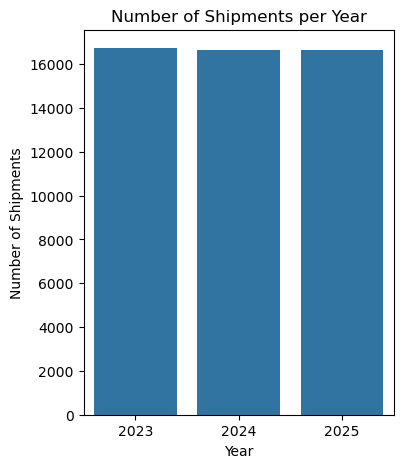

In [15]:
plt.figure(figsize=(4,5))
sns.barplot(data=yearly_shipments, x='Year', y='Number of Shipments')
plt.title('Number of Shipments per Year')
plt.xlabel('Year')
plt.ylabel('Number of Shipments')
plt.show()

In [16]:
monthly_shipments = (
    df.groupby([
        df['Shipment_Date'].dt.year.rename('Year'), 
        df['Shipment_Date'].dt.month.rename('Month')
    ])
    .size()
    .reset_index(name='Number of Shipments')
)
monthly_shipments.columns =['Year','Month','Number of Shipments']
monthly_shipments

,Year,Month,Number of Shipments
0,2023,1,1436
1,2023,2,1297
2,2023,3,1398
3,2023,4,1365
4,2023,5,1394
5,2023,6,1427
6,2023,7,1373
7,2023,8,1421
8,2023,9,1415
9,2023,10,1436


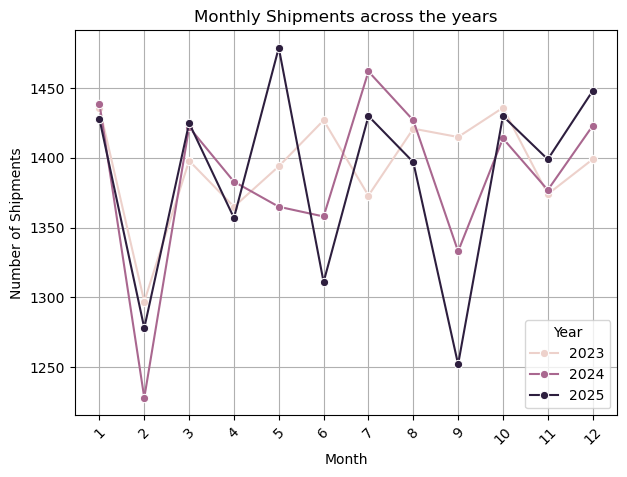

In [17]:
plt.figure(figsize = (7,5))
sns.lineplot(data = monthly_shipments, x='Month', y='Number of Shipments',hue = 'Year',marker='o')
plt.title( 'Monthly Shipments across the years')
plt.xlabel('Month')
plt.ylabel('Number of Shipments')
plt.xticks(range(1,13),rotation=45)
plt.grid(True)
plt.show()

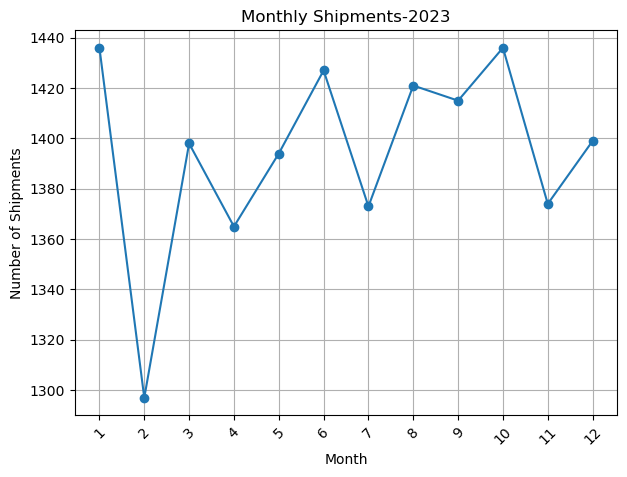

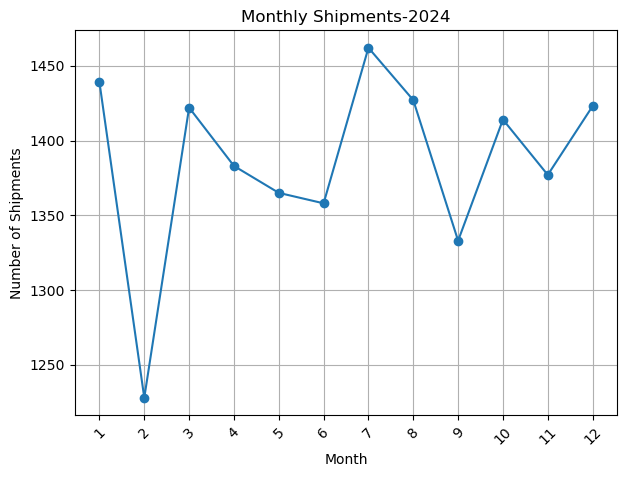

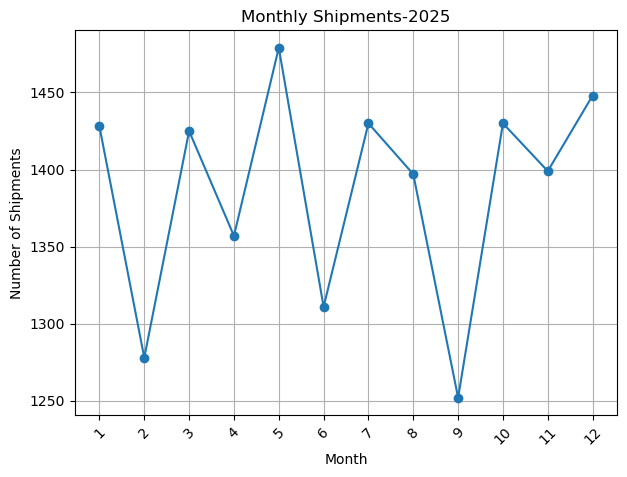

In [18]:
for year in monthly_shipments['Year'].unique():
    data = monthly_shipments[monthly_shipments['Year']==year]
    plt.figure(figsize = (7,5))
    plt.plot(data['Month'], data['Number of Shipments'], marker='o', label=str(year))
    plt.title(f'Monthly Shipments-{year}')
    plt.xlabel('Month')
    plt.ylabel('Number of Shipments')
    plt.xticks(range(1,13),rotation=45)
    plt.grid(True)
plt.show()  

In [19]:
weekly_shipments=(
    df_3years.groupby([
        df_3years['Shipment_Date'].dt.isocalendar().year.rename('Year'),
        df_3years['Shipment_Date'].dt.isocalendar().week.rename('Week')
    ])
    .size()
    .reset_index(name='Number_of_Shipments')

)

weekly_shipments

,Year,Week,Number_of_Shipments
0,2022,52,43
1,2023,1,341
2,2023,2,308
3,2023,3,322
4,2023,4,333
...,...,...,...
153,2025,49,293
154,2025,50,313
155,2025,51,331
156,2025,52,354


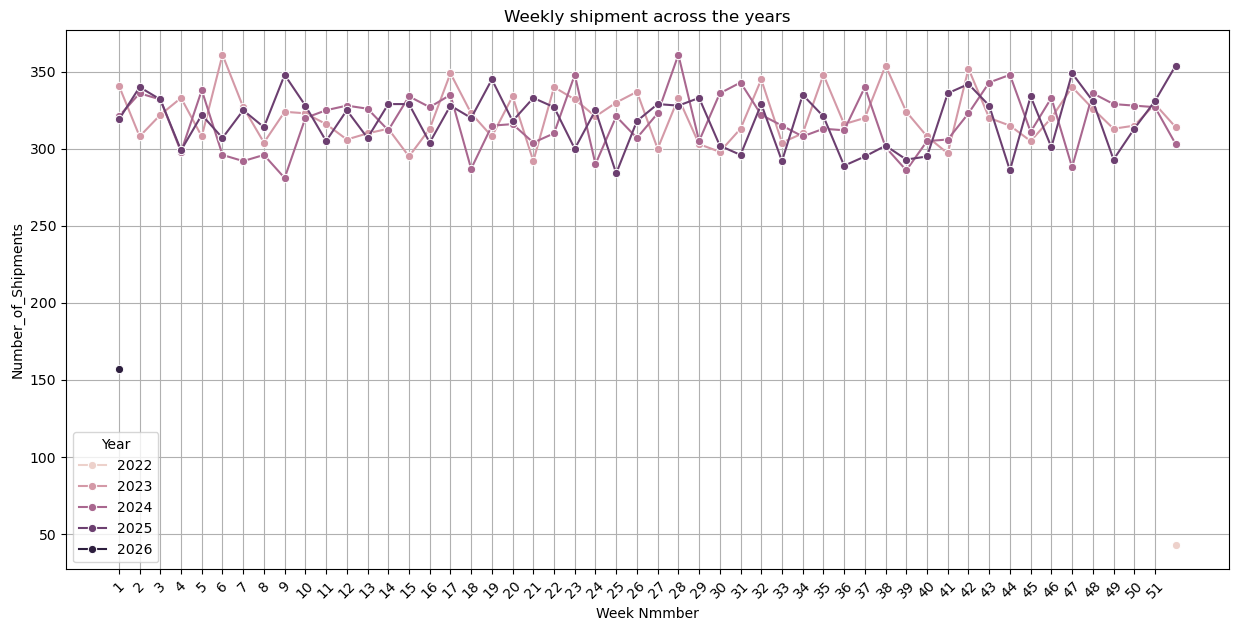

In [20]:
plt.figure(figsize=(15,7))
sns.lineplot(data=weekly_shipments, x='Week', y='Number_of_Shipments', hue = 'Year', marker = 'o')
plt.title('Weekly shipment across the years')
plt.xlabel('Week Nmmber')
plt.ylabel('Number_of_Shipments')
plt.xticks(range(1,52),rotation=45)
plt.grid(True)
plt.show()

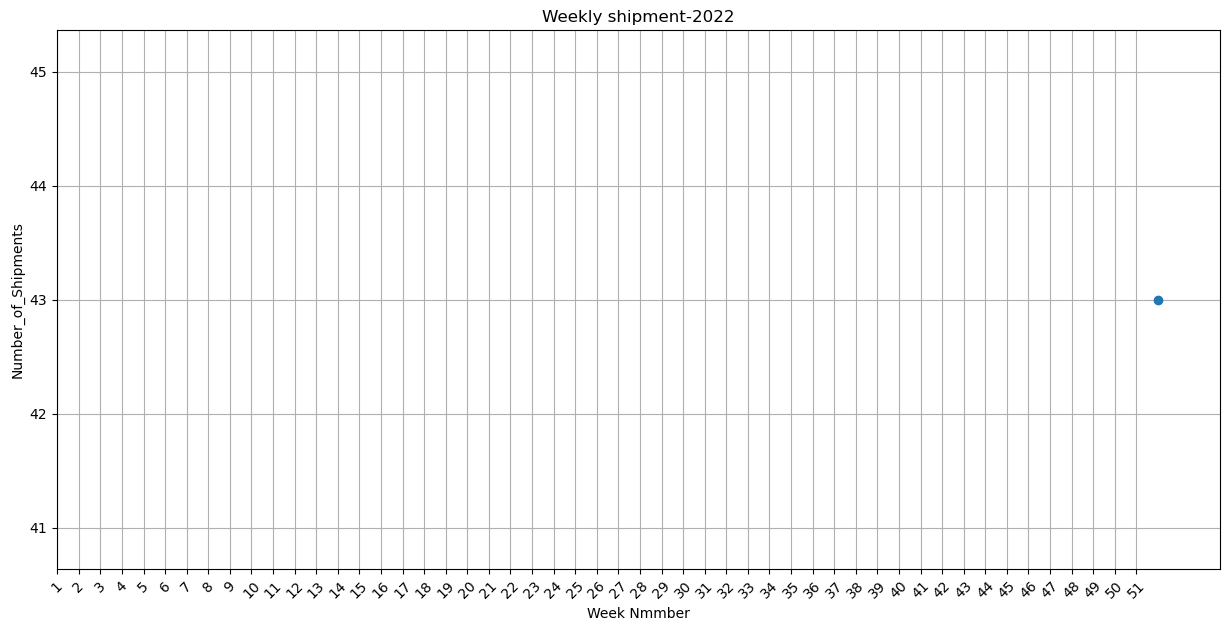

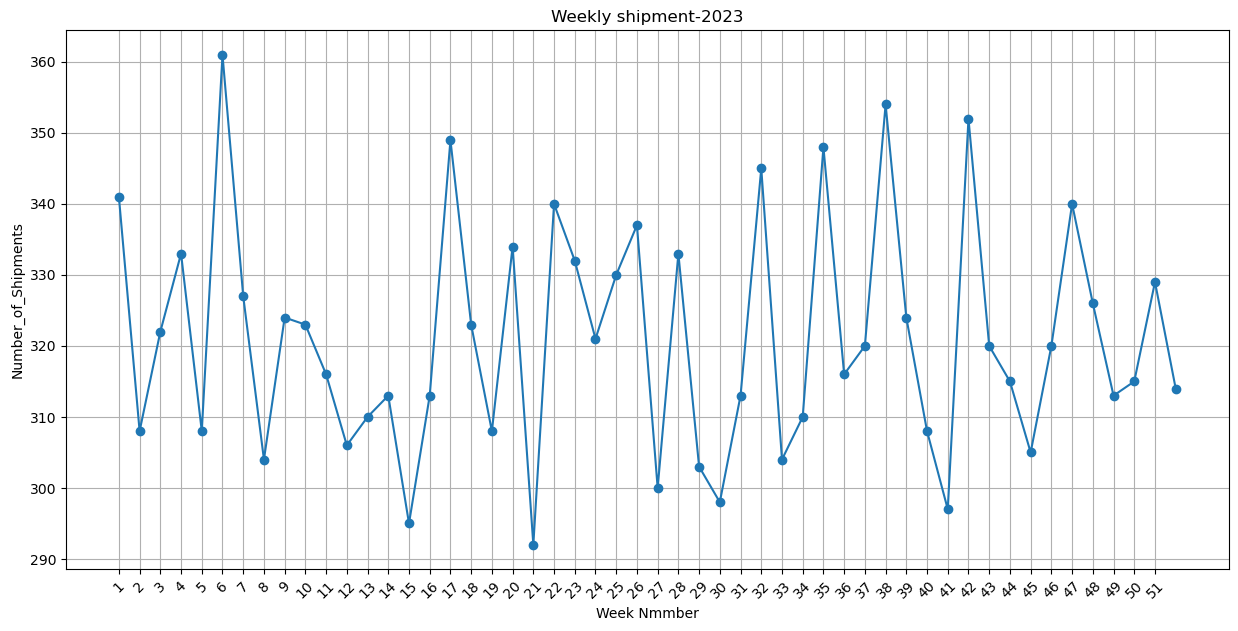

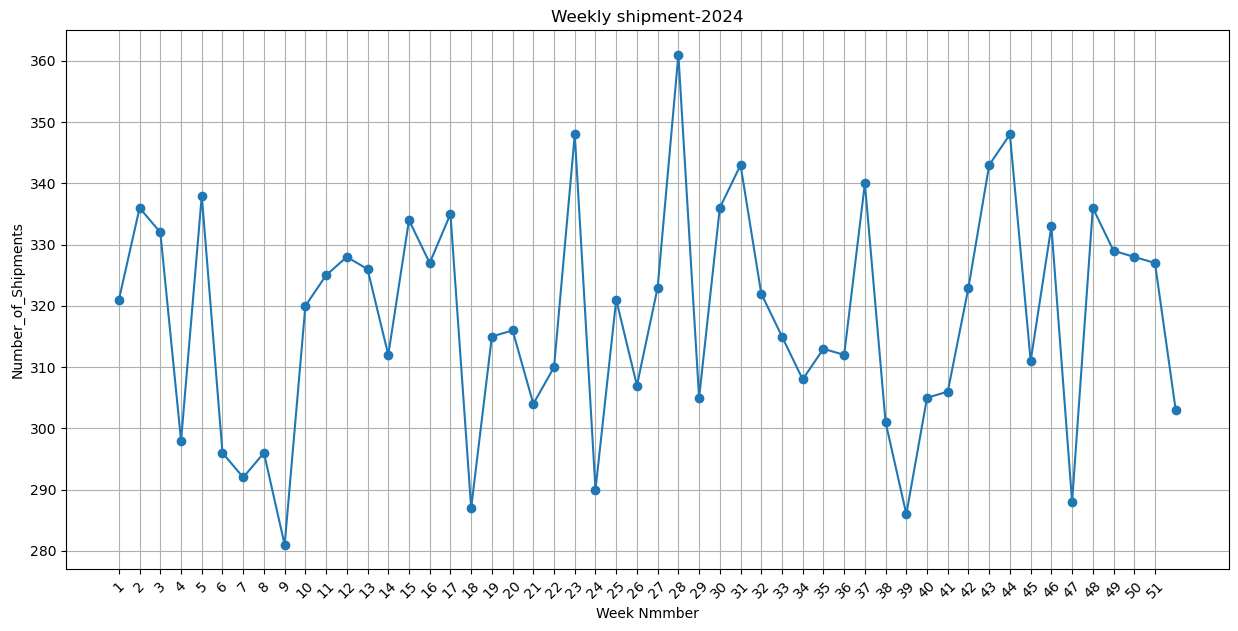

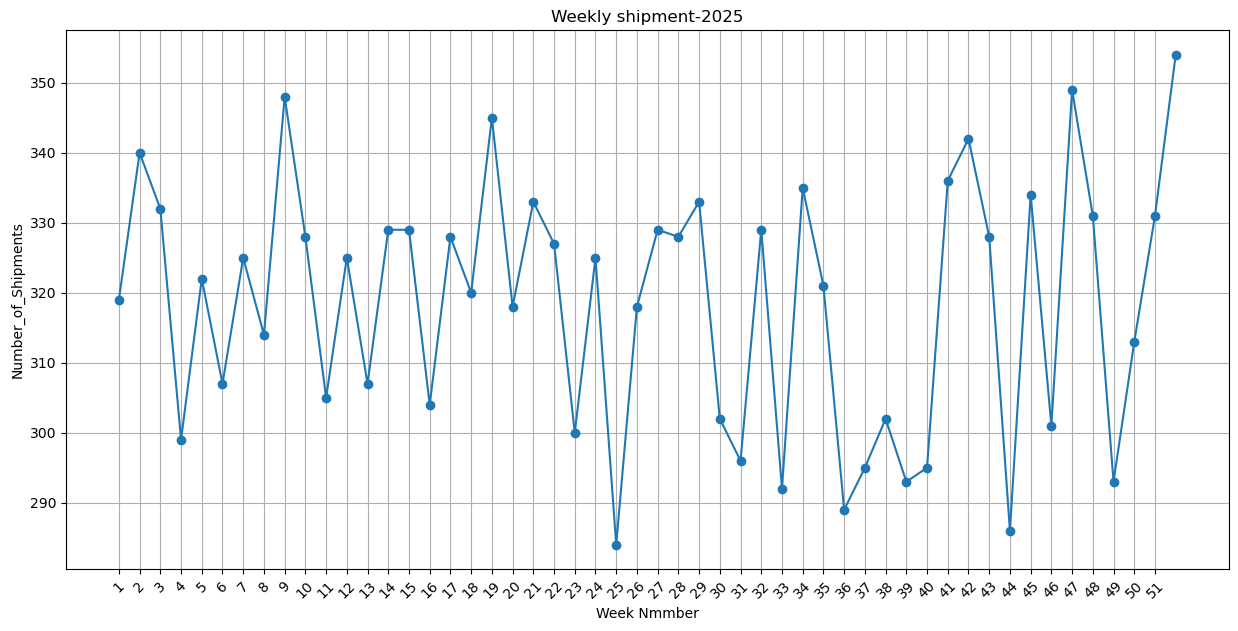

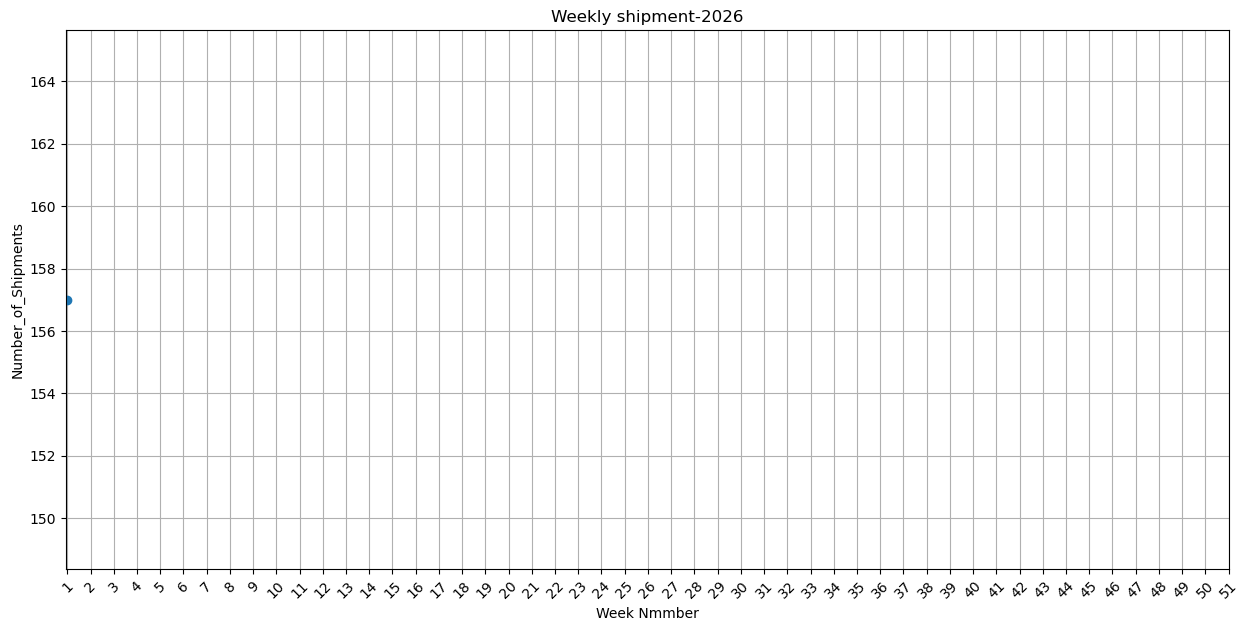

In [21]:
for year in weekly_shipments['Year'].unique():
    data=weekly_shipments[weekly_shipments['Year']==year]
    plt.figure(figsize=(15,7))
    plt.plot(data['Week'], data['Number_of_Shipments'], marker = 'o')
    plt.title(f'Weekly shipment-{year}')
    plt.xlabel('Week Nmmber')
    plt.ylabel('Number_of_Shipments')
    plt.xticks(range(1,52),rotation=45)
    plt.grid(True)
plt.show()

In [22]:
daily_shipments = (
    df.groupby(df['Shipment_Date'].dt.day_name()
)
  .size()
  .reindex(['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday'])
  .reset_index(name='Number of shipments')
)
daily_shipments


,Shipment_Date,Number of shipments
0,Monday,7132
1,Tuesday,7135
2,Wednesday,7159
3,Thursday,7279
4,Friday,7045
5,Saturday,7042
6,Sunday,7208


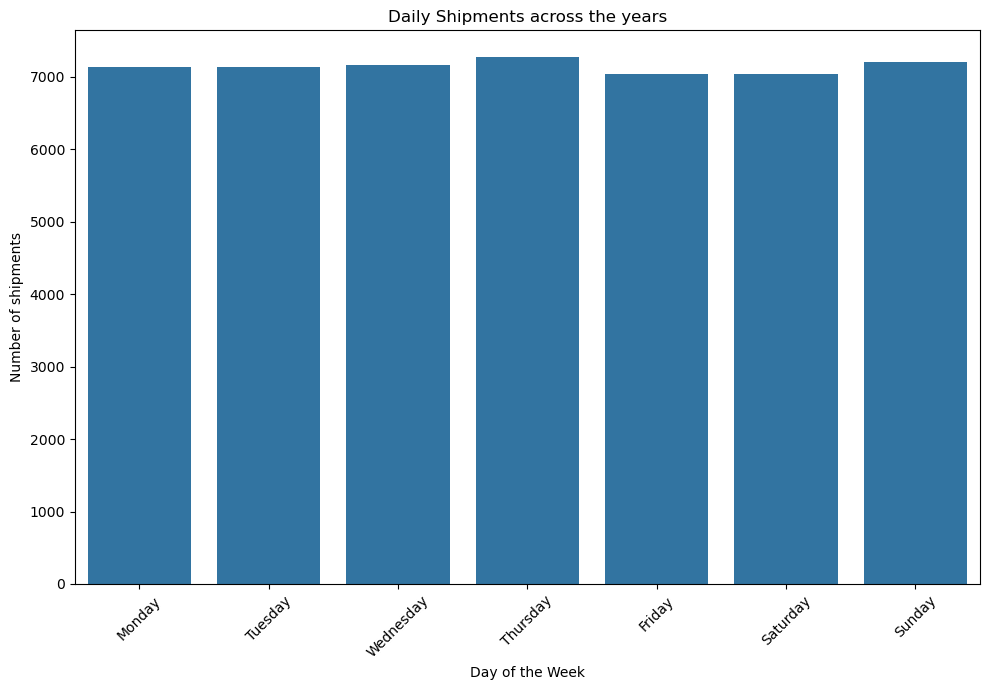

In [23]:
plt.figure(figsize=(10,7))
sns.barplot(data=daily_shipments, x='Shipment_Date', y= 'Number of shipments')
plt.title('Daily Shipments across the years')
plt.xlabel('Day of the Week')
plt.ylabel('Number of shipments')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


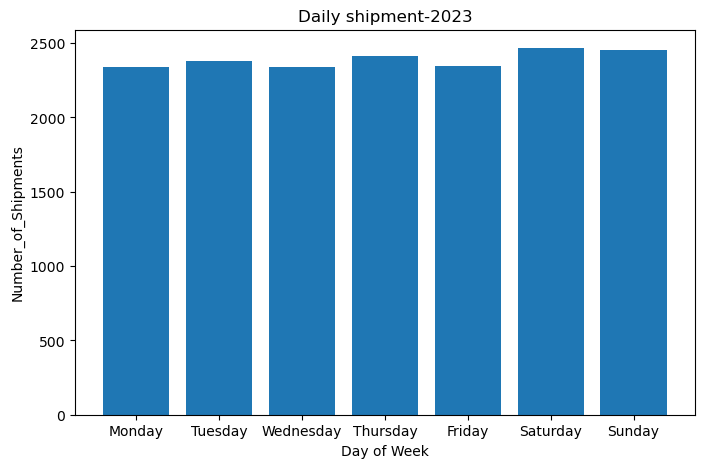

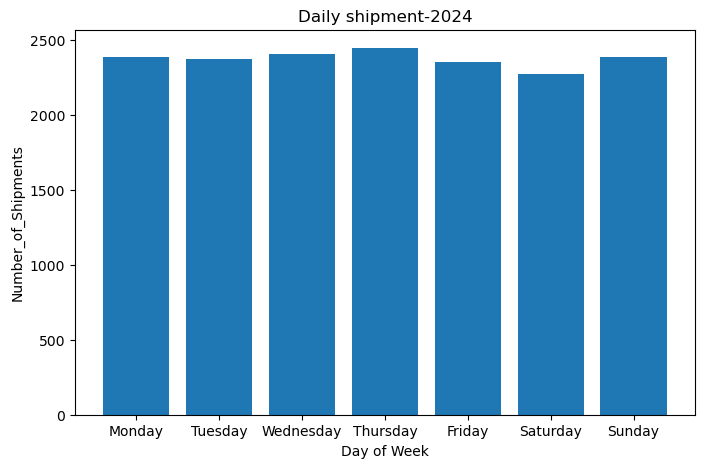

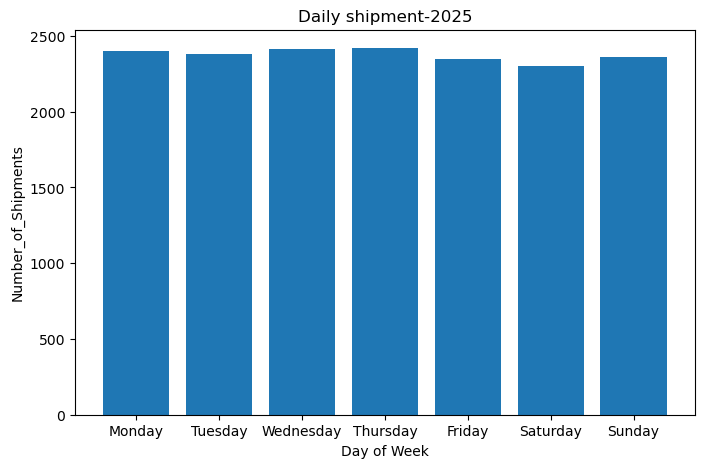

In [24]:
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
for year in [2023,2024,2025]:
    data = df[df['Shipment_Date'].dt.year==year]
    daily=(
    data['Shipment_Date']
    .dt.day_name().value_counts().reindex(day_order,fill_value=0))
    plt.figure(figsize=(8,5))
    plt.bar(daily.index,daily.values)
    plt.title(f'Daily shipment-{year}')
    plt.xlabel('Day of Week')
    plt.ylabel('Number_of_Shipments')
    
plt.show()

In [25]:
daily_2023=(
    df[df['Shipment_Date'].dt.year==2023]
    ['Shipment_Date'].dt.day_name().value_counts().reindex(day_order,fill_value=0))
daily_2023

Shipment_Date
Monday       2339
Tuesday      2380
Wednesday    2337
Thursday     2412
Friday       2345
Saturday     2467
Sunday       2455
Name: count, dtype: int64

In [26]:
daily_2024=(
    df[df['Shipment_Date'].dt.year==2024]
    ['Shipment_Date'].dt.day_name().value_counts().reindex(day_order,fill_value=0))
daily_2024

Shipment_Date
Monday       2390
Tuesday      2376
Wednesday    2407
Thursday     2447
Friday       2351
Saturday     2271
Sunday       2389
Name: count, dtype: int64

In [27]:
daily_2025=(
    df[df['Shipment_Date'].dt.year==2025]
    ['Shipment_Date'].dt.day_name().value_counts().reindex(day_order,fill_value=0))
daily_2025

Shipment_Date
Monday       2403
Tuesday      2379
Wednesday    2415
Thursday     2420
Friday       2349
Saturday     2304
Sunday       2364
Name: count, dtype: int64

In [28]:
busiest_month = monthly_shipments.loc[monthly_shipments['Number of Shipments'].idxmax()]

lowest_month = monthly_shipments.loc[monthly_shipments['Number of Shipments'].idxmin()]

print(busiest_month)
print(lowest_month)


Year                   2025
Month                     5
Number of Shipments    1479
Name: 28, dtype: int64
Year                   2024
Month                     2
Number of Shipments    1228
Name: 13, dtype: int64


In [29]:
busiest_week = weekly_shipments.loc[weekly_shipments['Number_of_Shipments'].idxmax()]

lowest_week = weekly_shipments.loc[weekly_shipments['Number_of_Shipments'].idxmin()]

print(busiest_week)
print(lowest_week)


Year                   2023
Week                      6
Number_of_Shipments     361
Name: 6, dtype: Int64
Year                   2022
Week                     52
Number_of_Shipments      43
Name: 0, dtype: Int64


In [30]:
busiest_day = daily.idxmax()

lowest_day = daily.idxmin()

print("overall busiest_day:",busiest_day, "_",daily.max(),"shipments")
print("overall lowest_day:",lowest_day, "_",daily.min(),"shipments")


overall busiest_day: Thursday _ 2420 shipments
overall lowest_day: Saturday _ 2304 shipments


In [31]:
df_3years['Shipping_Cost_NGN'].describe()

count    50000.000000
mean      4239.641031
std       2060.683806
min       1280.930000
25%       2828.032500
50%       3737.960000
75%       5096.750000
max      43296.210000
Name: Shipping_Cost_NGN, dtype: float64

In [32]:
average_shipping_cost = df_3years['Shipping_Cost_NGN'].mean()

print("average_shipping_cost: #", average_shipping_cost)

average_shipping_cost: # 4239.6410306


In [33]:
total_shipping_cost = df_3years['Shipping_Cost_NGN'].sum()

print("total_shipping_cost: #", total_shipping_cost)

total_shipping_cost: # 211982051.53


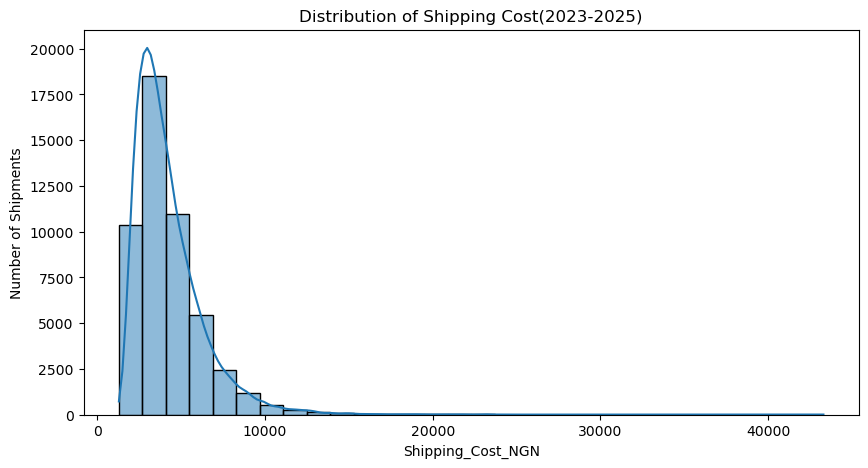

In [34]:
plt.figure(figsize=(10,5))
sns.histplot(df_3years['Shipping_Cost_NGN'], bins=30, kde=True)
plt.title('Distribution of Shipping Cost(2023-2025)')
plt.xlabel('Shipping_Cost_NGN')
plt.ylabel('Number of Shipments')
plt.show()



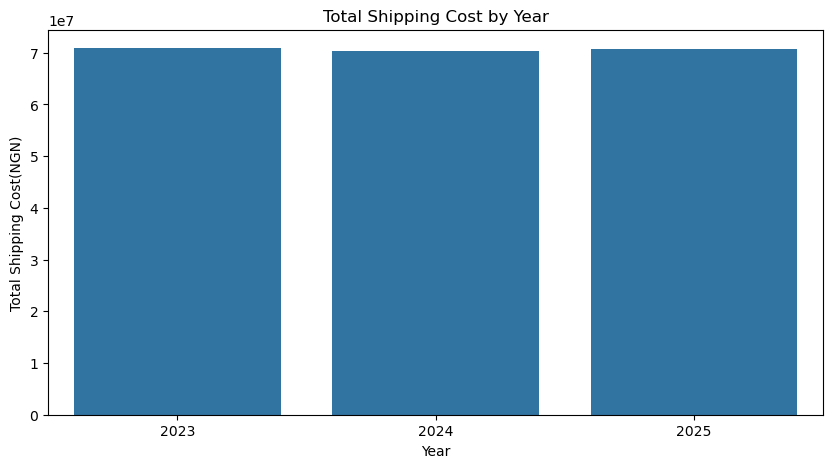

In [35]:
cost_by_year=(df_3years.groupby(df_3years['Shipment_Date'].dt.year)['Shipping_Cost_NGN'].sum().reset_index(name='Total Shipping Cost'))
cost_by_year

plt.figure(figsize=(10,5))
sns.barplot(data=cost_by_year, x='Shipment_Date', y= 'Total Shipping Cost')
plt.title('Total Shipping Cost by Year')
plt.xlabel('Year')
plt.ylabel('Total Shipping Cost(NGN)')
plt.show()


In [36]:
cost_by_year

,Shipment_Date,Total Shipping Cost
0,2023,70904251.17
1,2024,70367807.48
2,2025,70709992.88


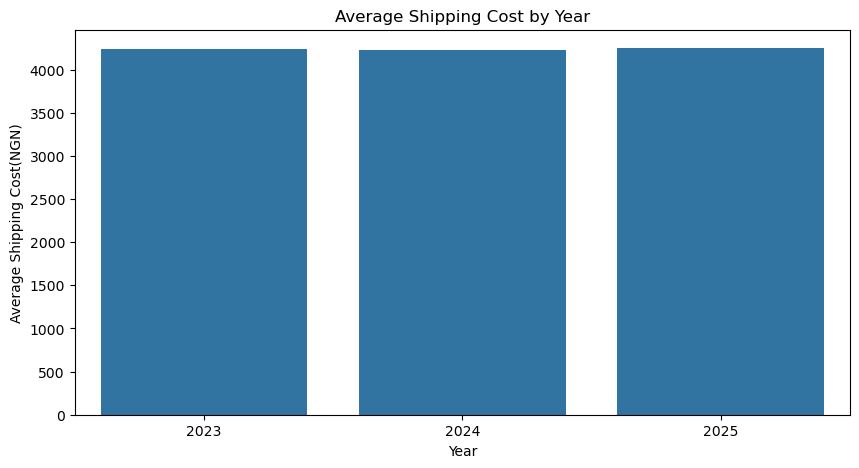

In [37]:
avg_cost_by_year=(df_3years.groupby(df_3years['Shipment_Date'].dt.year)['Shipping_Cost_NGN'].mean().reset_index(name='Average Shipping Cost'))
avg_cost_by_year

plt.figure(figsize=(10,5))
sns.barplot(data=avg_cost_by_year, x='Shipment_Date', y= 'Average Shipping Cost')
plt.title('Average Shipping Cost by Year')
plt.xlabel('Year')
plt.ylabel('Average Shipping Cost(NGN)')
plt.show()

In [38]:
avg_cost_by_year


,Shipment_Date,Average Shipping Cost
0,2023,4236.883846
1,2024,4231.123052
2,2025,4250.931398


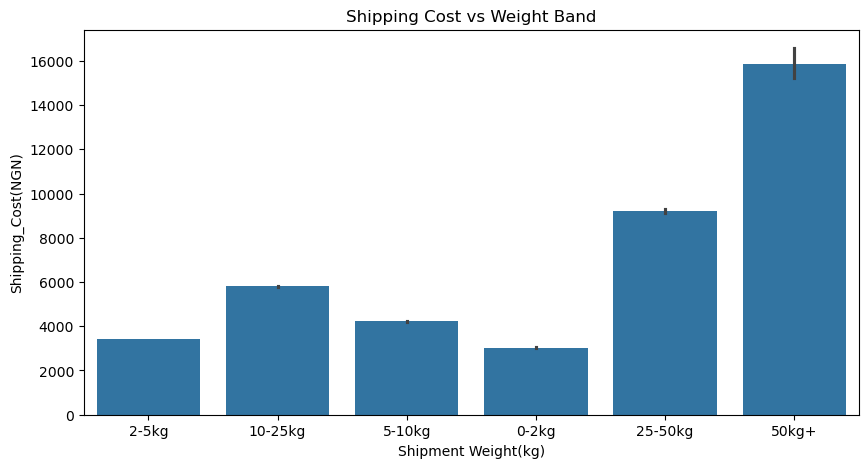

In [39]:
plt.figure(figsize=(10,5))
sns.barplot(data=df_3years, x='Weight_Band', y='Shipping_Cost_NGN')
plt.title('Shipping Cost vs Weight Band')
plt.xlabel('Shipment Weight(kg)')
plt.ylabel('Shipping_Cost(NGN)')
plt.show()

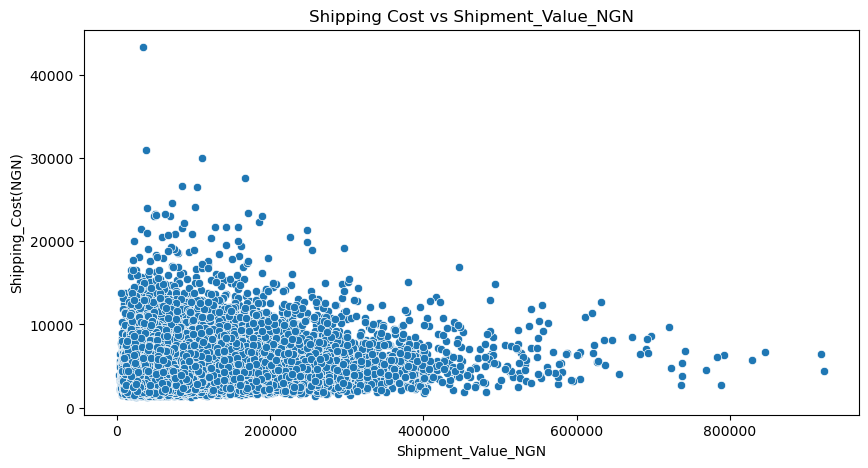

In [40]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=df_3years, x='Shipment_Value_NGN', y='Shipping_Cost_NGN')
plt.title('Shipping Cost vs Shipment_Value_NGN')
plt.xlabel('Shipment_Value_NGN')
plt.ylabel('Shipping_Cost(NGN)')
plt.show()

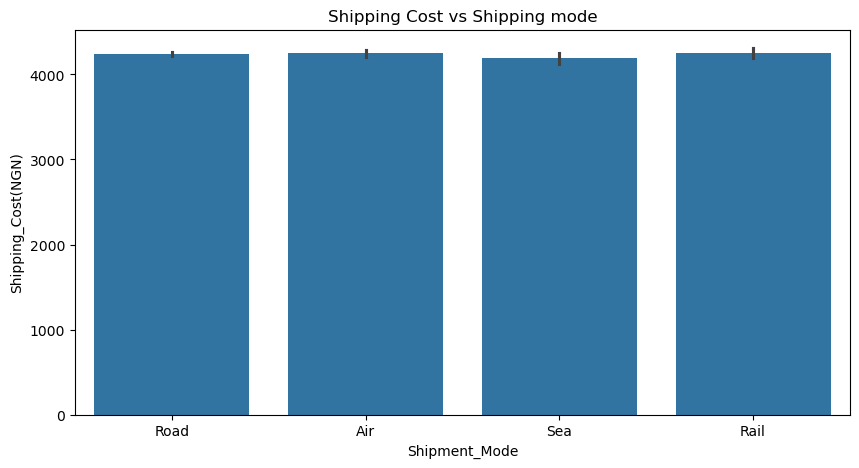

In [41]:
plt.figure(figsize=(10,5))
sns.barplot(data=df_3years, x='Shipping_Mode', y='Shipping_Cost_NGN')
plt.title('Shipping Cost vs Shipping mode')
plt.xlabel('Shipment_Mode')
plt.ylabel('Shipping_Cost(NGN)')
plt.show()

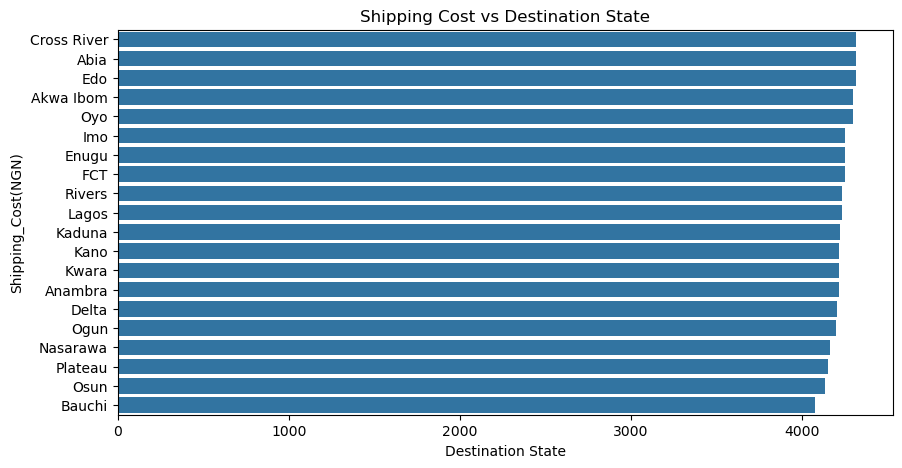

In [42]:
state_cost = (df_3years.groupby('Destination_State')['Shipping_Cost_NGN'].mean().sort_values(ascending=False).reset_index())
plt.figure(figsize=(10,5))
sns.barplot(data=state_cost, x='Shipping_Cost_NGN', y='Destination_State')
plt.title('Shipping Cost vs Destination State')
plt.xlabel('Destination State')
plt.ylabel('Shipping_Cost(NGN)')
plt.show()

In [43]:
state_cost.loc[state_cost['Shipping_Cost_NGN'].idxmax()]

Destination_State    Cross River
Shipping_Cost_NGN     4318.59037
Name: 0, dtype: object

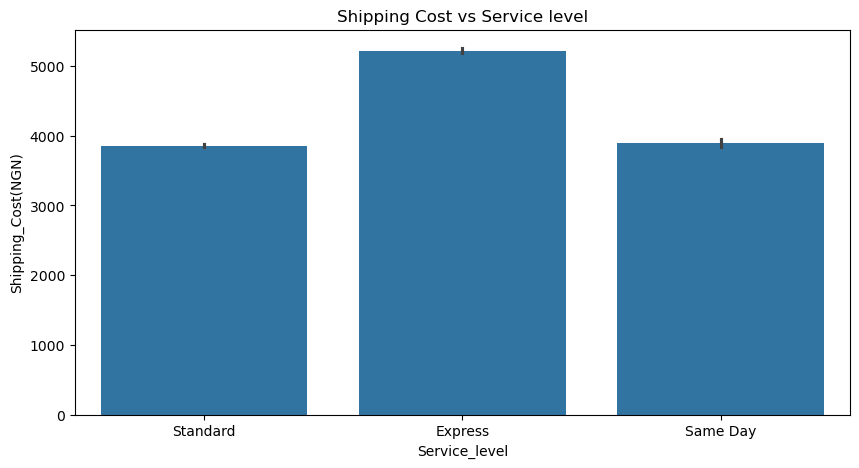

In [44]:
plt.figure(figsize=(10,5))
sns.barplot(data=df_3years, x='Service_Level', y='Shipping_Cost_NGN')
plt.title('Shipping Cost vs Service level')
plt.xlabel('Service_level')
plt.ylabel('Shipping_Cost(NGN)')
plt.show()

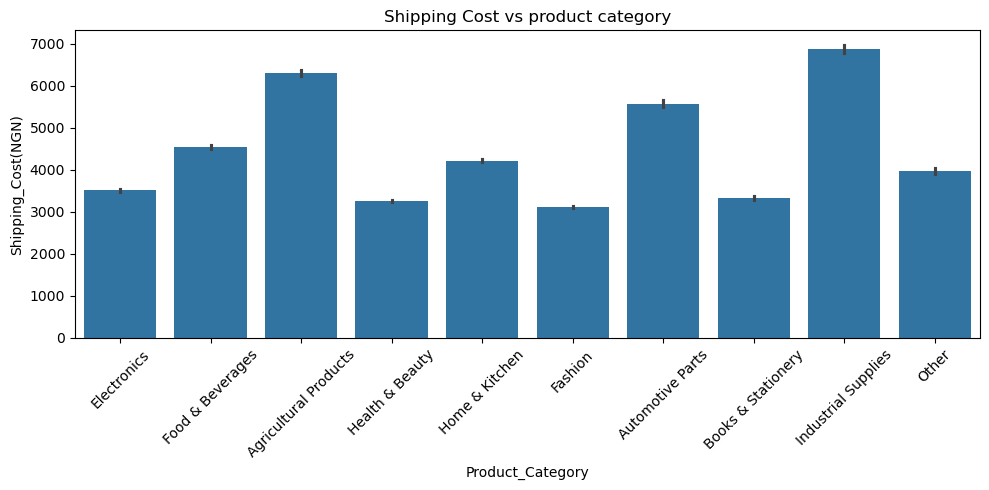

In [45]:
plt.figure(figsize=(10,5))
sns.barplot(data=df_3years, x='Product_Category', y='Shipping_Cost_NGN')
plt.title('Shipping Cost vs product category')
plt.xlabel('Product_Category')
plt.ylabel('Shipping_Cost(NGN)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [46]:
x= df_3years[
    ['Origin_City',               
     'Destination_State',          
'Destination_City',           
'Product_Category',                    
'Shipment_Value_NGN',                  
'Shipping_Mode',              
'Service_Level',              
'Payment_Method',             
'Shipment_Status',            
'Estimated_Delivery_Days',    
'Customer_Rating',                         
'Shipment_Weight_Kg']] 

y = df_3years['Shipping_Cost_NGN']

In [47]:
numeric_data = x.select_dtypes(include='number').copy()
numeric_data['Shipping_Cost_NGN'] = y
numeric_data.corr()

,Shipment_Value_NGN,Estimated_Delivery_Days,Customer_Rating,Shipment_Weight_Kg,Shipping_Cost_NGN
Shipment_Value_NGN,1.000000,0.011681,0.004404,0.200998,0.158791
Estimated_Delivery_Days,0.011681,1.000000,-0.007615,-0.003850,0.104121
Customer_Rating,0.004404,-0.007615,1.000000,0.002328,0.001887
Shipment_Weight_Kg,0.200998,-0.003850,0.002328,1.000000,0.797730
Shipping_Cost_NGN,0.158791,0.104121,0.001887,0.797730,1.000000


In [48]:
numerical_columns= [               
'Shipment_Value_NGN', 'Estimated_Delivery_Days',    
'Customer_Rating',                         
'Shipment_Weight_Kg','Shipping_Cost_NGN']

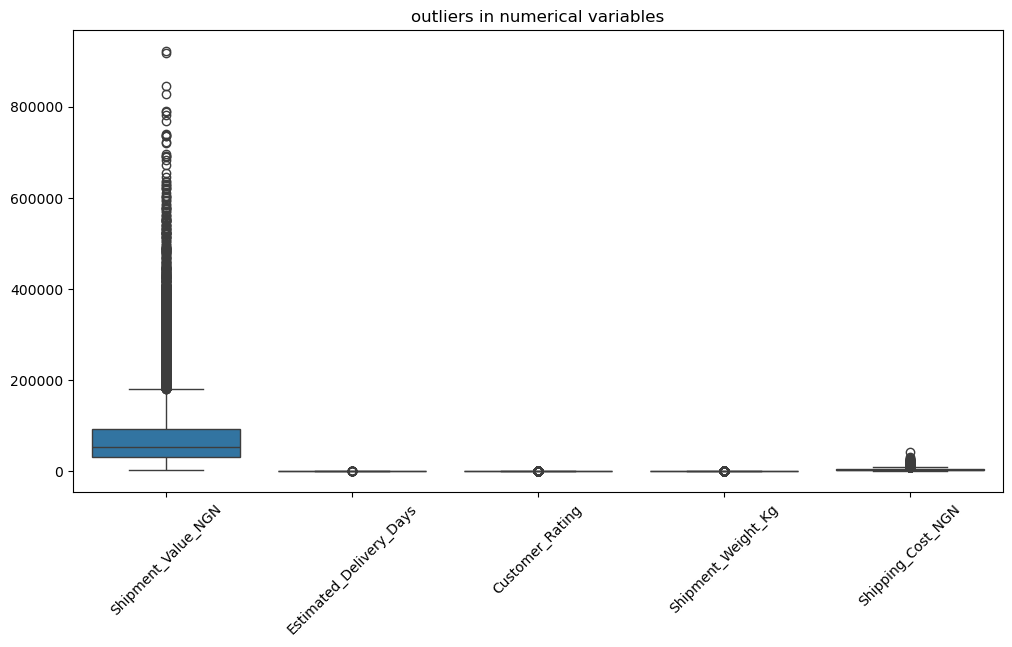

In [49]:
plt.figure(figsize=(12,6))
sns.boxplot(data = df_3years[numerical_columns])
plt.title('outliers in numerical variables')
plt.xticks(rotation=45)
plt.show()


In [57]:
for col in numerical_columns:
    Q1 = df_3years[col].quantile(0.25)
    Q3 = df_3years[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR

    df_3years = df_3years[(df_3years[col]>=lower) & (df_3years[col]<=upper)]
    df_3years=df_3years.reset_index(drop=True)
    

In [64]:
x_encoded = pd.get_dummies(df_3years[
    ['Origin_City',               
     'Destination_State',          
     'Destination_City',           
     'Product_Category',                                      
     'Shipping_Mode',              
     'Service_Level',              
     'Payment_Method',             
     'Shipment_Status']],

drop_first=True)

x_encoded.head()


,Origin_City_Benin City,Origin_City_Ibadan,Origin_City_Kano,Origin_City_Lagos,Origin_City_Onitsha,Origin_City_Port Harcourt,Destination_State_Akwa Ibom,Destination_State_Anambra,Destination_State_Bauchi,Destination_State_Cross River,...,Shipping_Mode_Sea,Service_Level_Same Day,Service_Level_Standard,Payment_Method_Card,Payment_Method_Cash on Delivery,Payment_Method_Wallet,Shipment_Status_Delayed,Shipment_Status_Delivered,Shipment_Status_In Transit,Shipment_Status_Returned
0,False,False,False,False,False,True,False,False,False,False,...,False,False,True,False,False,False,False,True,False,False
1,False,False,False,False,False,False,False,False,False,False,...,False,False,True,False,False,True,False,False,False,False
2,False,False,False,True,False,False,False,False,False,False,...,False,False,False,False,True,False,False,True,False,False
3,False,False,False,True,False,False,False,False,False,False,...,False,False,True,False,True,False,False,True,False,False
4,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


In [68]:
numerical_columns= [               
'Shipment_Value_NGN', 'Estimated_Delivery_Days',    
'Customer_Rating',                         
'Shipment_Weight_Kg']
x_numerical = df_3years[numerical_columns]
x = pd.concat([x_numerical, x_encoded],axis =1)
    
y= df_3years['Shipping_Cost_NGN']

In [69]:
x.shape

(42323, 92)

In [70]:
y.shape

(42323,)

In [71]:
xtrain,xtest,ytrain,ytest = train_test_split(x,y,random_state = 42, test_size = 0.2)

In [74]:
logr = LinearRegression()

In [75]:
logr.fit(xtrain,ytrain)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [76]:
y_pred = logr.predict(xtest)

In [77]:
y_pred[:10]

array([2787.20403936, 3866.48840491, 2476.24950279, 4280.532426  ,
       4274.04739745, 4380.67180699, 3768.44322083, 4205.00350725,
       3008.94462861, 3184.21308562])

In [78]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [79]:
mae = mean_absolute_error(ytest, y_pred)
rmse = mean_squared_error(ytest, y_pred)**0.5
r2 = r2_score(ytest, y_pred)


print("MAE:",mae)
print("RMSE:",rmse)
print("R2:",r2)

MAE: 655.4865324400122
RMSE: 847.2518684171281
R2: 0.5644069130280385


In [87]:
coefficients = pd.DataFrame({'variable': x.columns,'coefficient':logr.coef_})
coefficients.head()

,variable,coefficient
0,Shipment_Value_NGN,-0.000116
1,Estimated_Delivery_Days,350.683946
2,Customer_Rating,3.134726
3,Shipment_Weight_Kg,181.661382
4,Origin_City_Benin City,14.877262


In [92]:
coefficients['Absolute_coefficient'] = coefficients['coefficient'].abs()
coefficients = coefficients.sort_values('Absolute_coefficient',ascending = False)
coefficients.head(30)

,variable,coefficient,Absolute_coefficient
84,Service_Level_Standard,-1347.474152,1347.474152
83,Service_Level_Same Day,-1339.953259,1339.953259
1,Estimated_Delivery_Days,350.683946,350.683946
3,Shipment_Weight_Kg,181.661382,181.661382
91,Shipment_Status_Returned,-60.440613,60.440613
66,Destination_City_Umuahia,47.050527,47.050527
53,Destination_City_Lekki,45.849749,45.849749
41,Destination_City_Gwagwalada,-44.742762,44.742762
79,Product_Category_Other,42.706306,42.706306
74,Product_Category_Fashion,-41.930691,41.930691


In [80]:
rfr = RandomForestRegressor()

In [81]:
rfr.fit(xtrain,ytrain)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [82]:
y_pred = rfr.predict(xtest)

In [83]:
y_pred[:10]

array([2671.1247, 4002.6539, 2561.6816, 4449.7482, 4463.1529, 4098.5594,
       3606.796 , 4407.5557, 3071.3694, 3439.4043])

In [84]:
mae = mean_absolute_error(ytest, y_pred)
rmse = mean_squared_error(ytest, y_pred)**0.5
r2 = r2_score(ytest, y_pred)


print("MAE:",mae)
print("RMSE:",rmse)
print("R2:",r2)

MAE: 671.517433195511
RMSE: 868.5522611551249
R2: 0.542229482471154
